# Random Forest — parâmetros por F1 e threshold por GridSearchCV

F1 seleciona parâmetros e limiar, acompanhando Recall e Precision; AP/AUPRC é diagnóstico.
Na CV de parâmetros usa-se uma referência comum 0,50. O limiar operacional é escolhido
na grade interna, não imposto. A ordem é busca de parâmetros → threshold → validação.
Nenhum TEST é pontuado, e os dados já foram explorados historicamente.

Treino: `python -m fraud_detection.classification_search --family random_forest`.
Estatísticas completas: [random_forest_model_metrics.ipynb](random_forest_model_metrics.ipynb).
EXECUTAR_BUSCA=False lê relatórios; True executa em uma saída ainda não concluída.

**Grade ampliada solicitada:** 4 × 4 × 4 = 64 combinações. Os mesmos 31 thresholds
foram mantidos. A rodada com 8 combinações permanece preservada como histórico.
A reutilização dos scores coincidentes é validada por dados, versões e períodos.

In [1]:
# A busca só é executada quando explicitamente ativada.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from fraud_detection.data import load_config
from fraud_detection.classification_search import run
from fraud_detection.reporting import readable_table

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists(): ROOT = ROOT.parent
EXECUTAR_BUSCA = False
OUTPUT = ROOT
config = load_config(ROOT / "configs/experiment.yaml")
features = load_config(ROOT / "configs/ablation.yaml")
settings = load_config(ROOT / "configs/random_forest_gridsearch.yaml")
if EXECUTAR_BUSCA:
    run(config, features, settings, OUTPUT)
PREFIX = settings["experiment_name"]
METRICS, FIGURES = OUTPUT / "reports/metrics", OUTPUT / "reports/figures"
manifest_path = OUTPUT / "reports/experiments" / f"{PREFIX}_manifest.json"
if not manifest_path.exists(): raise FileNotFoundError("Execute python -m fraud_detection.classification_search.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
assert not manifest["test_evaluated"] and not manifest["validation_used_for_selection"]
def table(name): return pd.read_csv(METRICS / f"{PREFIX}_{name}.csv")
def figure(name): display(Image(filename=str(FIGURES / f"{PREFIX}_{name}.png"), width=1100))


## 1. Grade e três períodos separados

A grade pesquisa learning_rate, max_depth, n_estimators, reg_alpha (L1) e
reg_lambda (L2). Scaling, seleção de features e SMOTE ficam dentro do treino.
Os modelos dos folds usados para AP não veem a janela de threshold. O pipeline
ajustado antes dessa janela permanece congelado depois de escolher o limiar.

In [2]:
display({key: manifest[key] for key in ["best_params", "best_cv_score", "threshold", "search_fit_rows", "search_fit_time_max",
    "threshold_rows", "threshold_time_min", "threshold_time_max", "validation_rows", "validation_time_min",
    "combinations", "executed_grid_fits", "reused_grid_fits"]})
display(manifest["settings"]["param_grid"])


{'best_params': {'criterion': 'gini',
  'max_depth': 30,
  'max_features': 'sqrt',
  'min_samples_leaf': 4,
  'n_estimators': 100},
 'best_cv_score': 0.839251015721604,
 'threshold': 0.6,
 'search_fit_rows': 119920,
 'search_fit_time_max': 75810.0,
 'threshold_rows': 36213,
 'threshold_time_min': 75811.0,
 'threshold_time_max': 108793.0,
 'validation_rows': 54159,
 'validation_time_min': 108799.0,
 'combinations': 64,
 'executed_grid_fits': 112,
 'reused_grid_fits': 16}

{'n_estimators': [100, 160, 210, 300],
 'max_depth': [10, 14, 25, 30],
 'min_samples_leaf': [1, 2, 3, 4],
 'max_features': ['sqrt'],
 'criterion': ['gini']}

## 2. GridSearchCV e seleção por F1

Média e desvio de F1 usam somente os dois folds anteriores ao threshold.
Os ranks são recalculados nesses folds. O gráfico é um perfil da melhor F1 por
valor; outros parâmetros podem variar, então não é uma medida de efeito isolado.

,rank_test_f1,param_model__min_samples_leaf,param_model__max_depth,param_model__n_estimators,param_model__max_features,param_model__criterion,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_test_average_precision
0,1,4,30,100,sqrt,gini,0.8393,0.0104,0.7862,0.9001,0.7915
1,1,4,25,100,sqrt,gini,0.8393,0.0104,0.7862,0.9001,0.7915
2,3,4,14,100,sqrt,gini,0.8339,0.0157,0.7777,0.8989,0.7883
3,4,4,30,300,sqrt,gini,0.8327,0.0039,0.7801,0.8930,0.7832
4,4,4,25,300,sqrt,gini,0.8327,0.0039,0.7801,0.8930,0.7832
5,6,3,14,210,sqrt,gini,0.8316,0.0028,0.7740,0.8988,0.7879
6,6,4,30,160,sqrt,gini,0.8316,0.0028,0.7740,0.8988,0.7870
7,6,4,25,160,sqrt,gini,0.8316,0.0028,0.7740,0.8988,0.7870
8,9,4,25,210,sqrt,gini,0.8289,0.0001,0.7740,0.8923,0.7776
9,9,4,30,210,sqrt,gini,0.8289,0.0001,0.7740,0.8923,0.7778


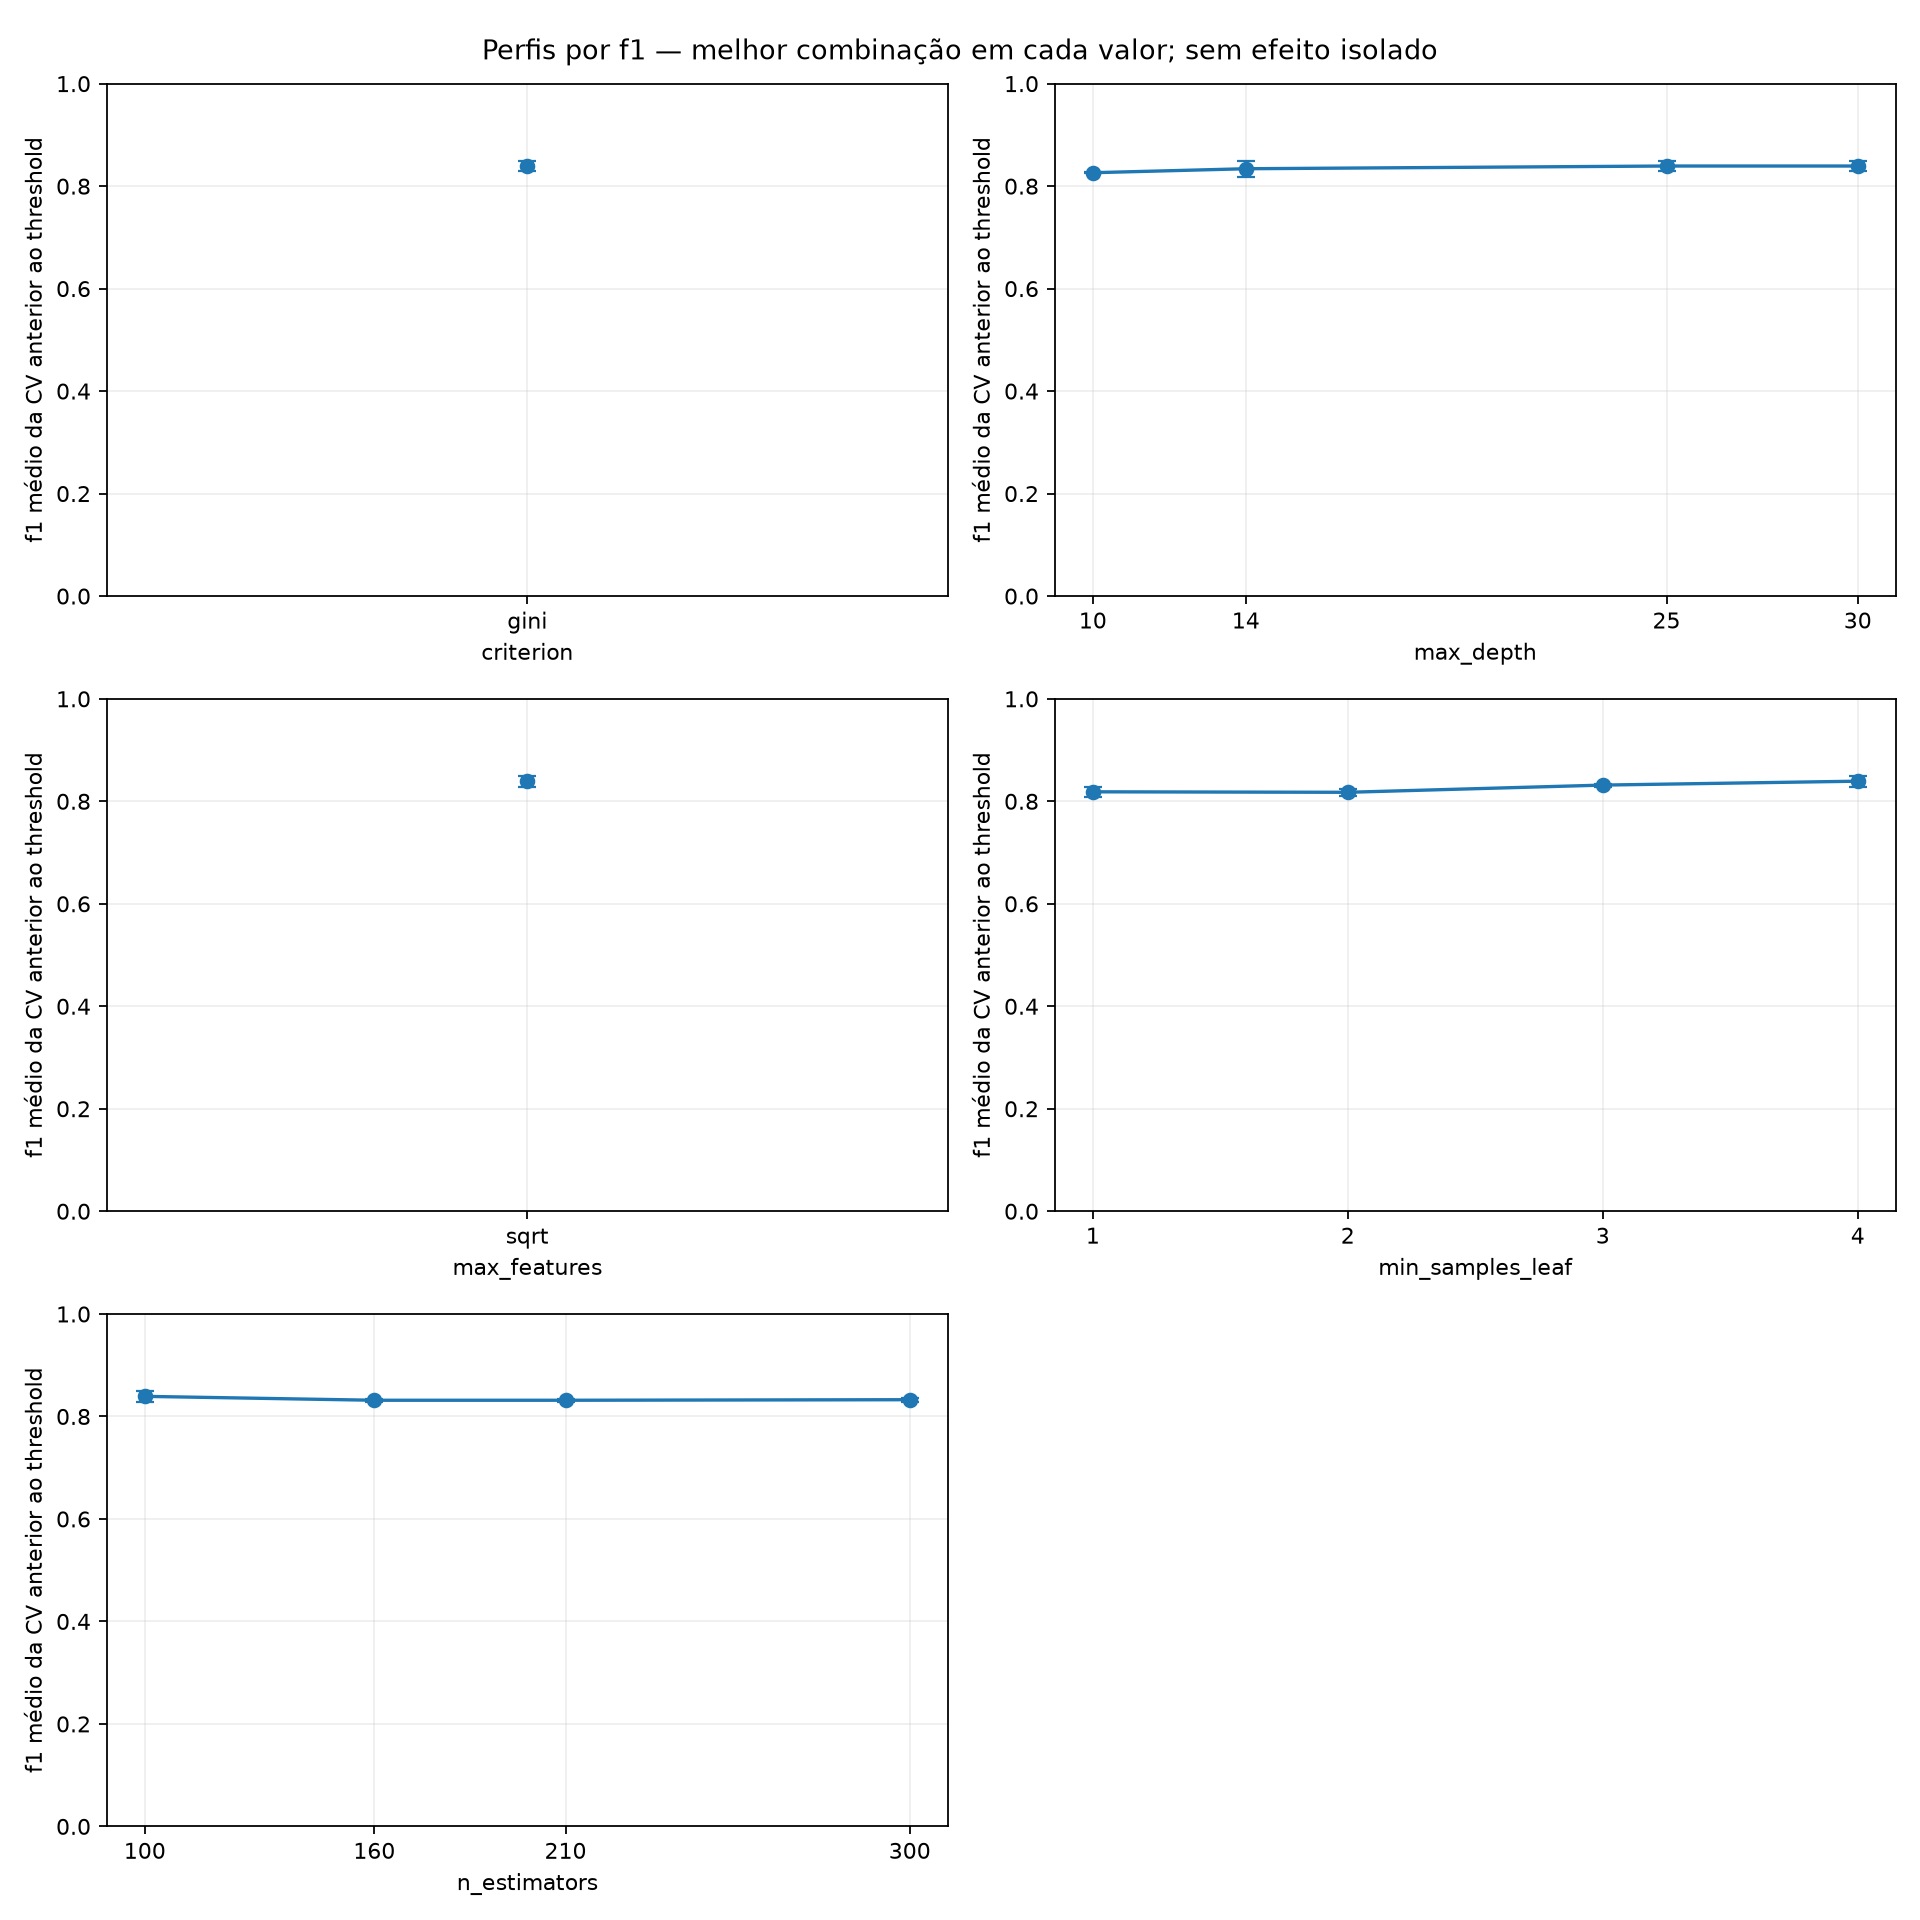

In [3]:
grid = table("results").sort_values("rank_test_f1")
columns = ["rank_test_f1", "param_model__min_samples_leaf", "param_model__max_depth",
           "param_model__n_estimators", "param_model__max_features", "param_model__criterion",
           "mean_test_f1", "std_test_f1", "mean_test_recall", "mean_test_precision", "mean_test_average_precision"]
display(grid[columns].head(12).style.format(precision=4))
figure("parameters")


## 3. GridSearchCV do threshold

AP usa scores contínuos e não muda com o threshold. A grade do limiar usa F1,
com Precision/Recall complementares. FrozenEstimator impede refits. A janela
reservada escolhe o limiar; a validação seguinte fica fora de ambas as escolhas.

,Limiar de alerta,F1 (%),Recall (%),Precision (%),AP (score),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas
0,"0,0000",0.50%,100.00%,0.25%,"0,7964",90,36.123,0
1,"0,0010",1.52%,97.78%,0.77%,"0,7964",88,11.377,2
2,"0,0050",2.17%,97.78%,1.10%,"0,7964",88,7.918,2
3,"0,0100",3.36%,96.67%,1.71%,"0,7964",87,5.005,3
4,"0,0200",6.34%,95.56%,3.28%,"0,7964",86,2.535,4
5,"0,0300",9.63%,93.33%,5.08%,"0,7964",84,1.571,6
6,"0,0500",17.06%,92.22%,9.40%,"0,7964",83,800,7
7,"0,0750",26.60%,92.22%,15.54%,"0,7964",83,451,7
8,"0,1000",36.53%,91.11%,22.84%,"0,7964",82,277,8
9,"0,1250",46.55%,90.00%,31.40%,"0,7964",81,177,9


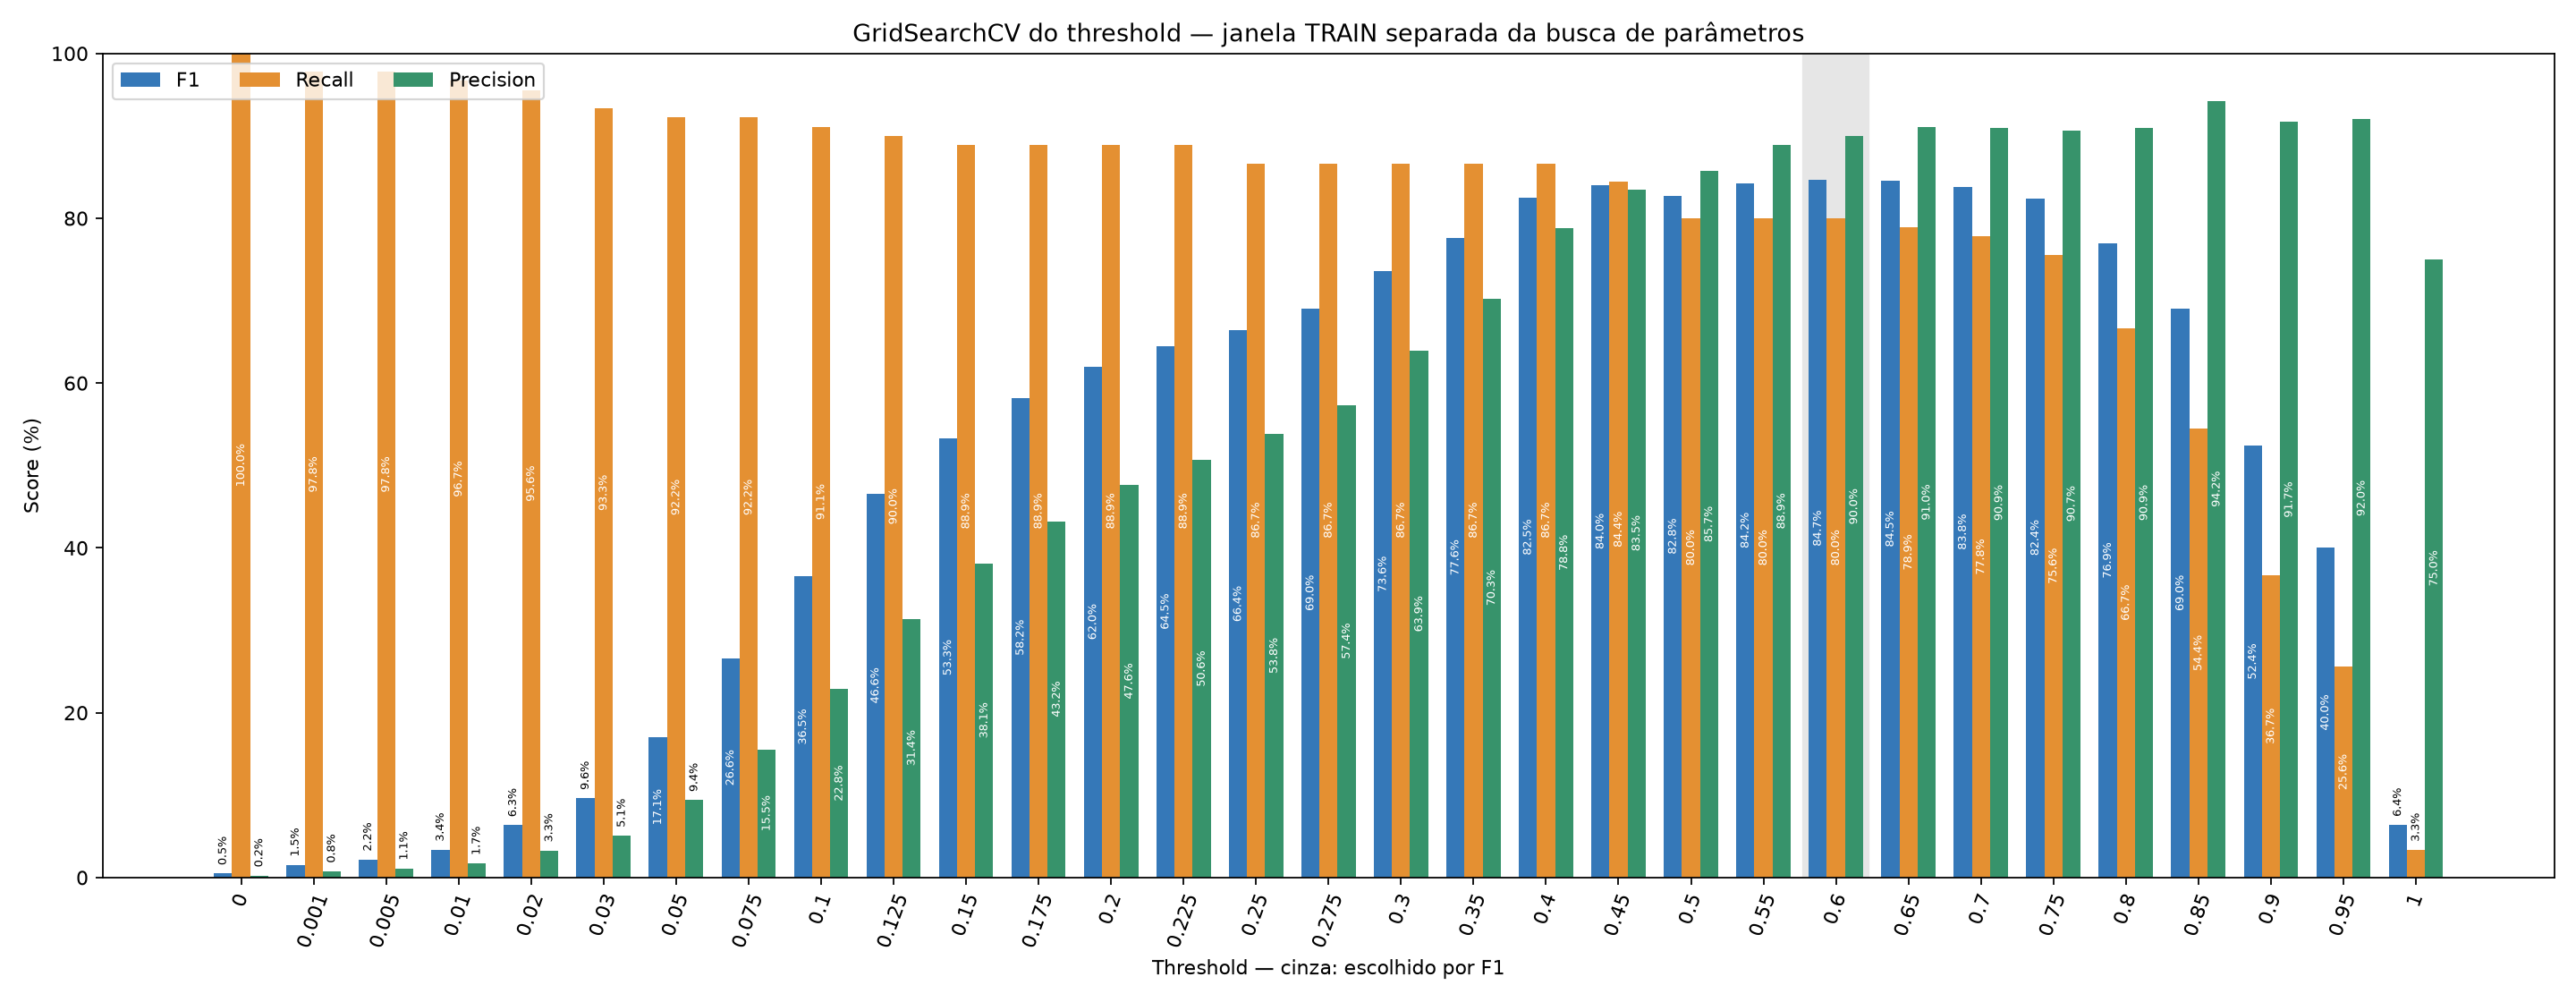

**Threshold escolhido na janela interna: 0.6000.**

In [4]:
thresholds = table("thresholds")
display(readable_table(thresholds[["threshold", "f1", "recall", "precision", "average_precision", "tp", "fp", "fn"]]))
figure("thresholds")
display(Markdown(f"**Threshold escolhido na janela interna: {manifest['threshold']:.4f}.**"))


## 4. Validação após congelar parâmetros e threshold

O mesmo pipeline usado na janela de threshold é aplicado à validação posterior,
sem refit ou calibração. Não é TEST. O histórico já explorou esses períodos;
confirmação independente exige dados novos. O notebook de estatísticas apresenta
matriz, PR/AP, ROC, calibração, métricas por classe, importâncias e erros por faixa.

,Receita,Origem,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta,alerts,Taxa de alertas (%),accuracy,negative_predictive_value,false_positive_rate,false_negative_rate,false_discovery_rate,false_omission_rate,prevalence,mcc,cohen_kappa,pr_auc_trapezoid,rows,positives,negatives
0,Random Forest f1 + SMOTE,Validação temporal TRAIN posterior ao ajuste do threshold; histórico explorado,"0,6973",73.33%,75.00%,71.74%,"0,9758",87.49%,99.98%,"0,0143","0,0012",54.102,13,11,33,"0,6000",46,0.08%,"0,9996","0,9998","0,0002","0,2500","0,2826","0,0002","0,0008","0,7333","0,7331","0,6939",54.159,44,54.115


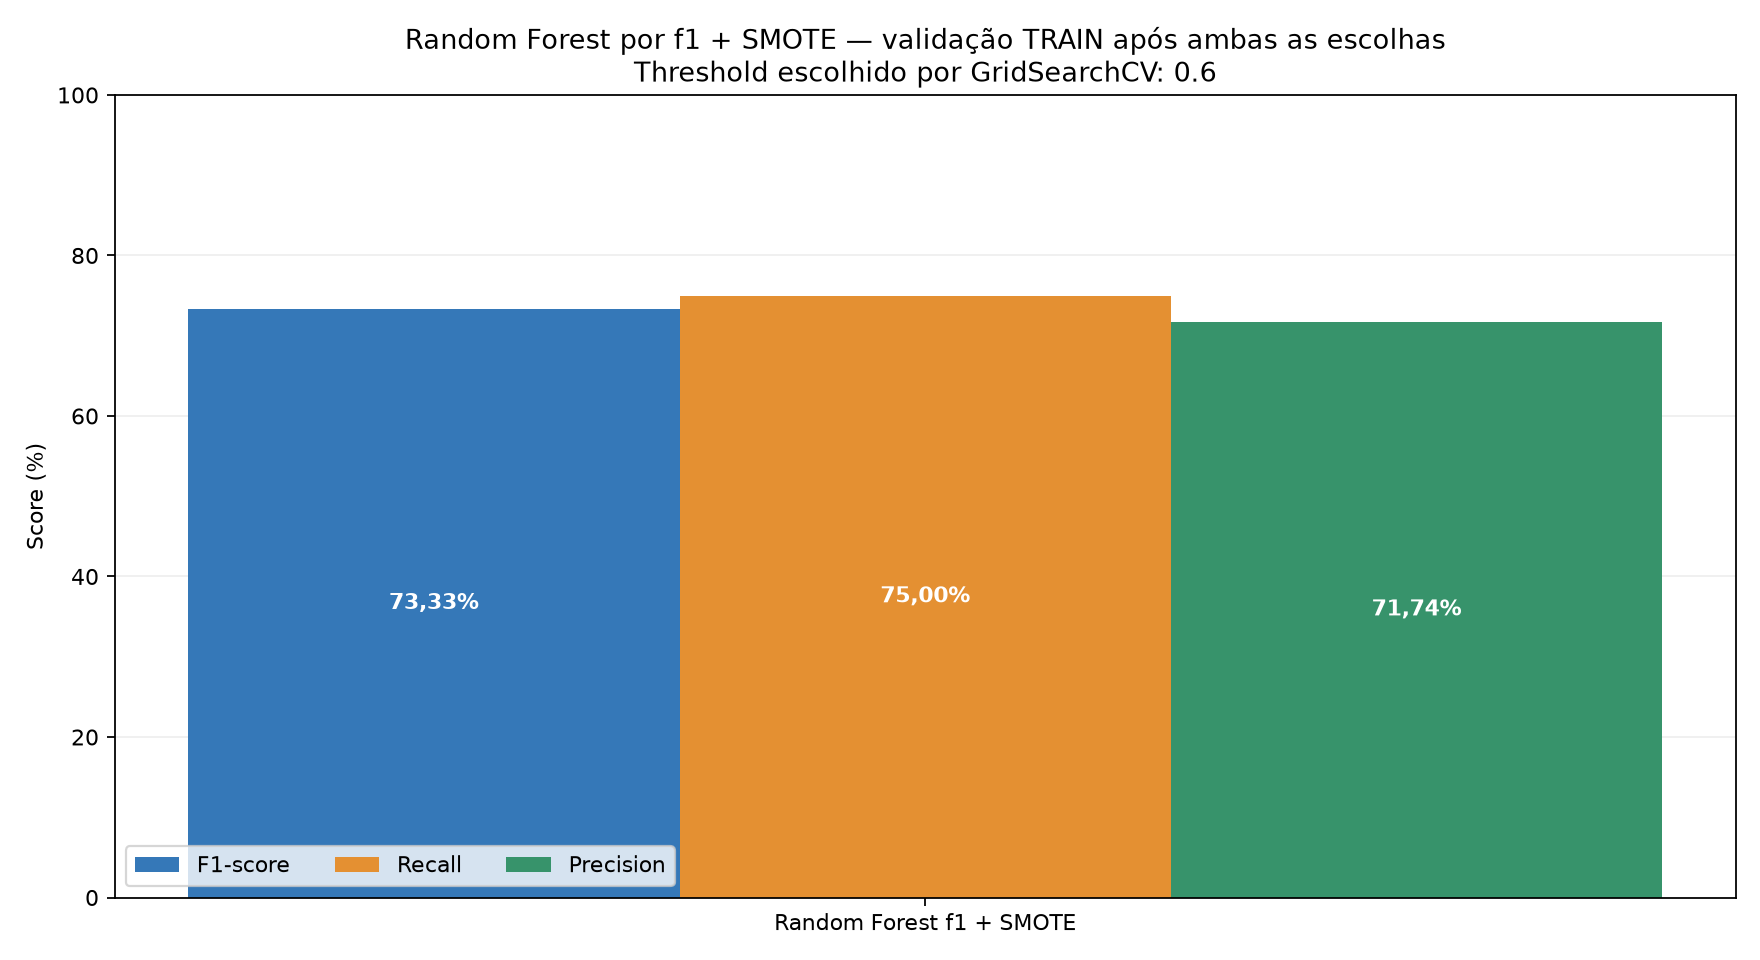

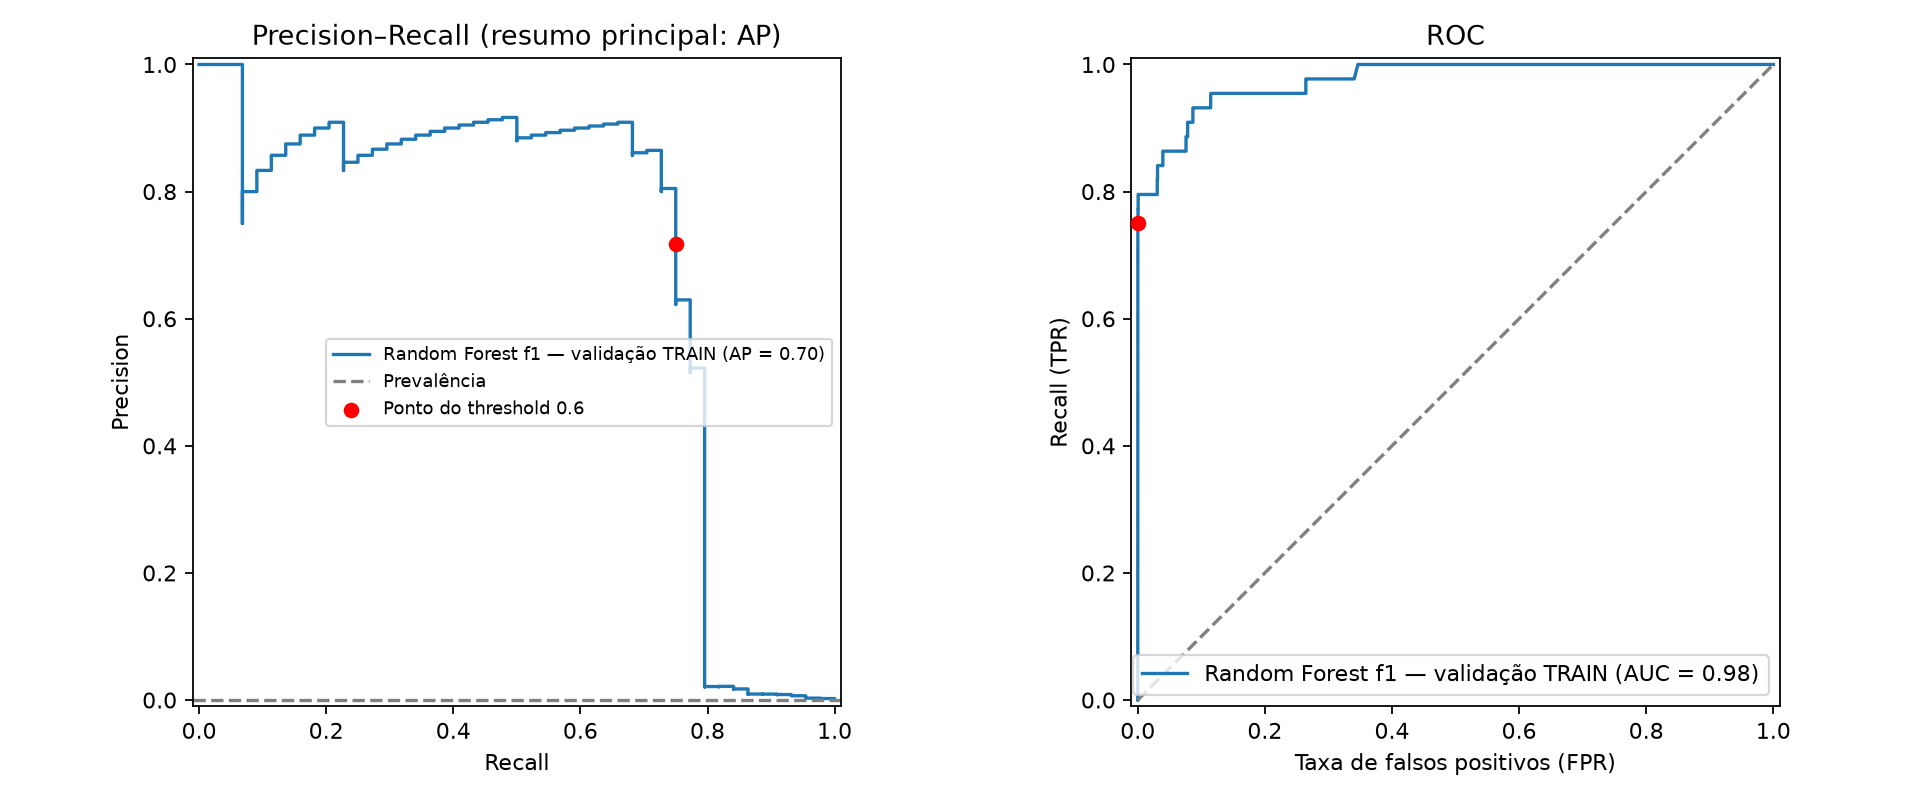

['F1 equilibra Precision e Recall; AP permanece diagnóstico quando F1 é a métrica de seleção.',
 'Seleção usa somente os folds anteriores à janela de threshold; limiar final é ajustado por F1 nessa janela.',
 'Na CV de parâmetros, F1/Recall/Precision usam a referência comum 0,50; o limiar operacional não fica fixado nesse valor.',
 'Validação TRAIN ficou fora de ambas as escolhas nesta rodada, mas o histórico já explorou esses dados.',
 'O mesmo pipeline congelado usado no threshold é aplicado à validação, sem refit posterior ou calibração.',
 'Não houve novo TEST; confirmação independente exige dados novos.']

In [5]:
display(readable_table(table("validation")))
figure("model_f1_recall_precision")
figure("pr_roc")
display(manifest["limitations"])
